In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import halfnorm, beta, lognorm

## What is a prior predictive check?

In Bayesian MMM, because the model and priors are all specified, we can check whether our chosen priors generate plausible business outcomes *even before observing any real data*. This allows us to sanity check whether our chosen priors are reasonable.

Recap: remember our model:
$$
y_t \sim \mathcal{N}(\hat y_t,\sigma)
$$

Our prediction $\hat y_t$ depends on parameters such as:
- Adstock decay ($\alpha$)
- Saturation (EC50)
- Channel contribution coefficients ($\beta$)
- Baseline revenue and control effects

We assign priors to these parameters. We can then randomly sample parameter values from those priors and simulate revenue.

This gives us a distribution of possible revenue outcomes before looking at the observed revenue.

## Let's implement a simple prior predictive check

In [3]:
n_simulations = 10000

# Priors
baseline = np.random.normal(150000, 20000, n_simulations)
beta_tv = np.random.normal(40000, 10000, n_simulations)
sigma = np.abs(np.random.normal(10000, 3000, n_simulations))

# Simplified TV saturation
tv_saturation = 0.5

# Simulate predicted revenue
expected_revenue = baseline + beta_tv * tv_saturation

# Add observation noise
simulated_revenue = np.random.normal(
    expected_revenue,
    sigma
)

{'whiskers': [<matplotlib.lines.Line2D at 0x112dbf710>,
 'caps': [<matplotlib.lines.Line2D at 0x112dbfc50>,
 'boxes': [<matplotlib.lines.Line2D at 0x112dbe5a0>],
 'medians': [<matplotlib.lines.Line2D at 0x112df81a0>],
 'fliers': [<matplotlib.lines.Line2D at 0x112df8440>],
 'means': []}

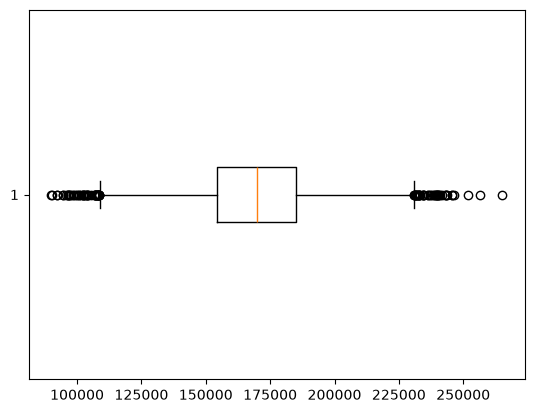

In [4]:
plt.boxplot(simulated_revenue, orientation='horizontal')

### Knowledge checkpoint

**Question 1: Suppose your prior predictive simulations suggest that FreshBite could generate weekly revenue anywhere from -$2 million to $5 million. What would this tell you about your priors or model?**

Answer 1: In this case, we know our dataset has revenue ranging between 170K-300K. So if we got a revenue range from -2M to 5M in our prior predictive change, we would know our priors and/or model are poorly specified. In the real world, we should be able to have historical revenue to understand whether the prior predictive check produces a reasonable range of values - if not, we should also be able to rely on subject matter expertise to produce a reasonable range of values. In this specific case, it likely suggests we should refine our priors and/or model until our prior predictive check produces a more reasonable range.

**Question 2: Why shouldn't we simply adjust our priors until the simulated revenue closely matches the actual revenue in our dataset?**

Answer 2: We are interested in the ability of our model to discover the correct parameters - in the real world we don't know the actual revenue and or parameter values, so we should pretend as if we don't know them in this case as well.

**Question 3: Suppose the prior predictive simulations produce realistic revenue values, but TV contributes 90% of total marketing revenue in nearly every simulation. What might this indicate, and what would you investigate?**

Answer 3: I would check on the parameters going into the prior predictive check for all channels (TV, social, search, display) - beta and saturation - and make sure that everything looks correct. This might indicate that there is just a typo or error in one of these specifications.

Refinement: Specifically, we can check:
* Prior assumptions: Are our beta and saturation priors accurately represented?
* Parameterization: Are all channels using consistent spend units and transformations?
* Model structure: Is our model correctly specified?

### Applying this in practice

In [5]:
df = pd.read_csv("../data/freshbite_marketing_data_masked.csv")

df["revenue"].describe()

count       156.000000
mean     219885.253787
std       17722.297617
min      172525.555275
25%      207883.208018
50%      219279.300644
75%      233470.539688
max      272432.755408
Name: revenue, dtype: float64

{'whiskers': [<matplotlib.lines.Line2D at 0x113361130>,
 'caps': [<matplotlib.lines.Line2D at 0x113360ef0>,
 'boxes': [<matplotlib.lines.Line2D at 0x1133617c0>],
 'medians': [<matplotlib.lines.Line2D at 0x11340ab70>],
 'fliers': [<matplotlib.lines.Line2D at 0x11329f8f0>],
 'means': []}

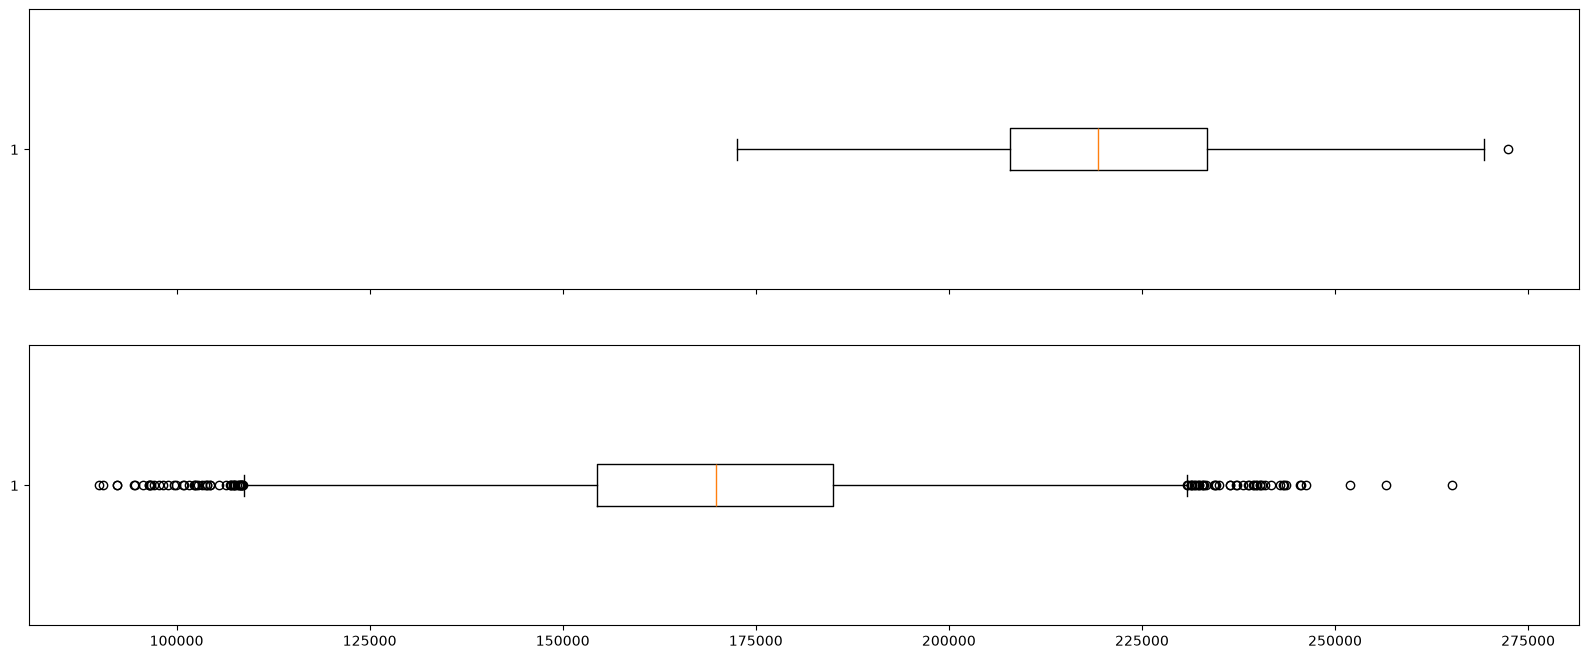

In [13]:
fig, ax = plt.subplots(2, 1, figsize=(20,8), sharex=True)

ax[0].boxplot(df["revenue"], orientation='horizontal')
ax[1].boxplot(simulated_revenue, orientation='horizontal')

Text(0.5, 1.0, 'True vs. simulated revenue')

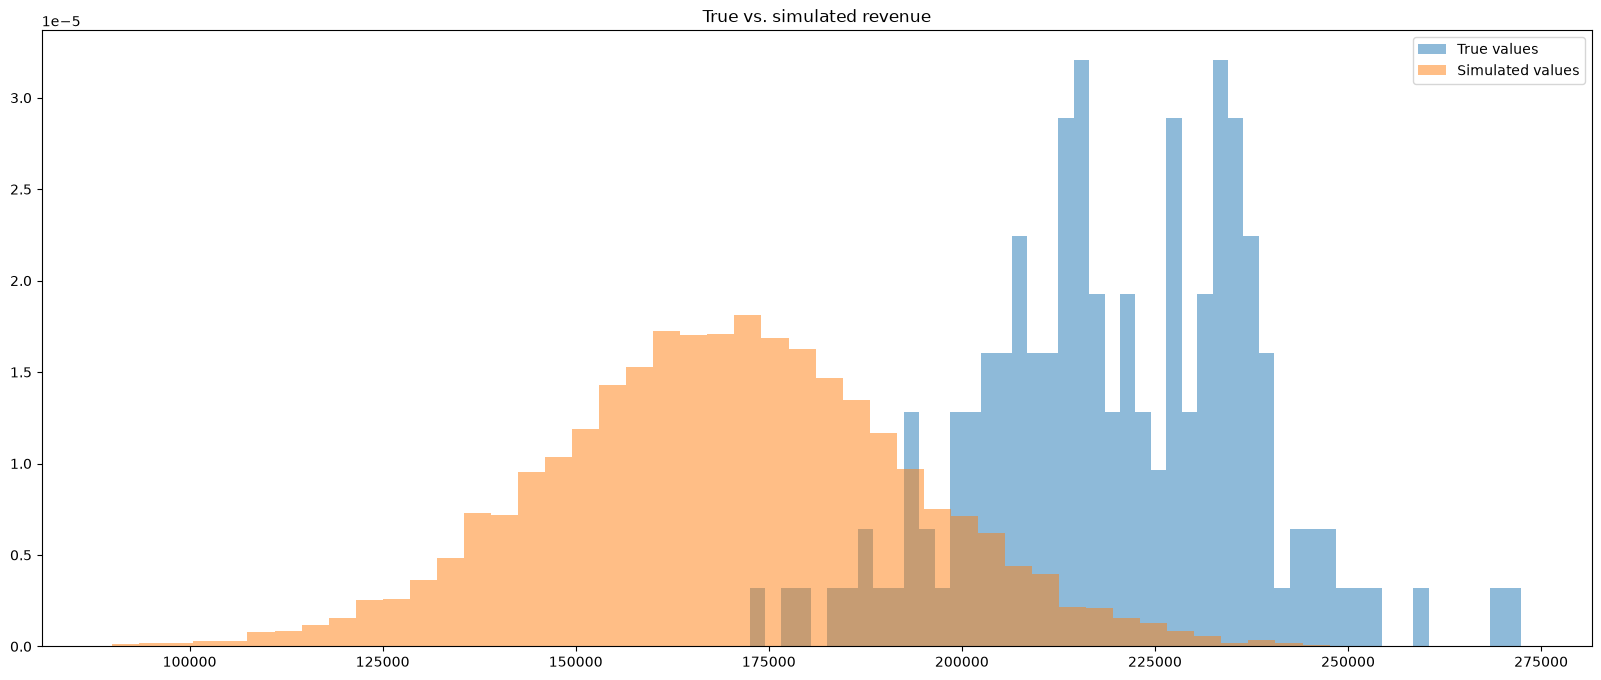

In [28]:
fig, ax = plt.subplots(1, 1, figsize=(20, 8))
ax.hist(df["revenue"], bins=50, alpha=0.5, density=True, label='True values')
ax.hist(simulated_revenue, bins=50, alpha=0.5, density=True, label='Simulated values')
ax.legend()
ax.set_title('True vs. simulated revenue')

### Check three things 
* Is the simulated revenue on a plausible scale?
* Is the distribution excessively wide?
* Does it allow implausible negative revenue values?

The prior predictive check passes all three checks - plausible scale, range of distribution, no negative values. While the distribution is noticeably lower than the true distribution, we can note that the true revenue includes contributions from social, search, display as well which is not the case for the simplified simulated values used for the prior predictive check.

### Last check for understanding

Assume we have two candidate prior specificiations:

Specification A:
* Alpha: Beta(2,2)
* Beta HalfNormal(100,000)
* Sigma: HalfNormal(50,000)

Specification B:
* Alpha: Beta(2,2)
* Beta HalfNormal(10,000)
* Sigma: HalfNormal(5,000)

**Question: Is specification B necessarily better than A because it produces a narrower prior predictive distribution?**

Answer: No, not necessarily. The width of the prior predictive distribution is reflective of the strengths of our beliefs - specification B would mean that we have stronger prior beliefs, so the beta/sigma priors are less dispersed than specification A, which is much more weakly informed priors. In either case, the observed data (likelihood) should update our priors toward the actual posterior distribution, though the amount of the update will also depend on the dispersion of the priors.

Note: The objective is not to minimize uncertainty. It's to represent uncertainty honestly.